In [24]:
# Install required OCR dependency
!pip install easyocr

# Cognitive assistant that reads medicine bottle labels (OCR + keyword extraction + speech)
import sys, re, glob, cv2, easyocr, os, urllib.request

# Initialize the reader outside or catch download timeout
try:
    reader = easyocr.Reader(['en'], gpu=False) # Fallback to CPU to avoid CUDA mismatches if any
except Exception as e:
    print(f"Error initializing EasyOCR: {e}")
    reader = None

FIELDS = {
    'Dosage':  r'(\d+\s?(?:mg|mcg|g|ml|iu)\b)',
    'Expiry':  r'(?:exp(?:iry)?\.?\s*(?:date)?[:\-\s]*)(\d{1,2}[/\-]\d{2,4}|\w{3}\s?\d{2,4})',
    'Batch':   r'(?:batch|b\.?\s?no\.?|lot)[:\-\s]*([A-Z0-9]+)',
    'Usage':   r'((?:take|use|apply)[^.\n]*)',
}

def preprocess(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
    return cv2.createCLAHE(2.0, (8, 8)).apply(g)

def read_label(path):
    if reader is None:
        return "OCR Reader not initialized", {}
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"Could not load image at path: {path}")
    lines = reader.readtext(preprocess(img), detail=0)
    text = '\n'.join(lines)
    info = {k: re.findall(p, text, re.I) for k, p in FIELDS.items()}
    return text, info

def speak(msg):
    # Prevent hanging on headless system
    pass

if __name__ == '__main__':
    # Prepare a directory and sample image if none exist
    if not os.path.exists('medicine_images'):
        os.makedirs('medicine_images')

    # Fetch sample if directory is empty
    existing_files = glob.glob('medicine_images/*.*')
    if not existing_files:
        print("No local medicine images found. Downloading a sample...")
        # Verified highly reliable public test image link from raw github
        sample_url = "https://raw.githubusercontent.com/tesseract-ocr/test/master/testing/phototest.tif"
        sample_path = "medicine_images/sample_label.jpg"
        try:
            headers = {'User-Agent': 'Mozilla/5.0'}
            req = urllib.request.Request(sample_url, headers=headers)
            with urllib.request.urlopen(req) as response, open(sample_path, 'wb') as out_file:
                out_file.write(response.read())
            existing_files = [sample_path]
            print("Successfully downloaded sample image.")
        except Exception as e:
            print(f"Could not download sample image: {e}")

    # Only process command line arguments that end with common image extensions
    passed_args = [p for p in sys.argv[1:] if p.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
    paths = passed_args or existing_files

    for p in paths:
        try:
            text, info = read_label(p)
            print(f"\n=== {p} ===\n{text}\n--- Extracted ---")
            for k, v in info.items():
                print(f"{k}: {v or 'not found'}")
            summary = ', '.join(f"{k} {v[0]}" for k, v in info.items() if v) or "No details detected"
            print("Assistant:", summary)
            speak(summary)
        except Exception as err:
            print(f"\n[Error processing {p}]: {err}")

No local medicine images found. Downloading a sample...
Successfully downloaded sample image.

=== medicine_images/sample_label.jpg ===
This is a lot of 12 point text to test the
ocr code and see if it works on
all types
of file format:
The quick brown dog jumped over the
lazy fox. The quick brown dog jumped
over the
fox The quick brown
jumped over the lazy fox: The
brown
jumped over the lazy fox.
dog
lazy
quick
dog
--- Extracted ---
Dosage: not found
Expiry: not found
Batch: ['of']
Usage: not found
Assistant: Batch of


Detected Emotion: angry
Response: Take a deep breath. Let's slow down and try again.


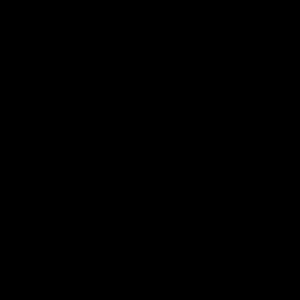

In [21]:
# Install missing dependencies
!pip install deepface tf-keras opencv-python

import cv2
import numpy as np
from deepface import DeepFace
from google.colab.patches import cv2_imshow

RESPONSES = {
    'happy':    "You look happy! Keep up the great mood.",
    'sad':      "You seem down. Want to hear a joke or take a short break?",
    'angry':    "Take a deep breath. Let's slow down and try again.",
    'fear':     "Everything is okay. I'm here to help.",
    'surprise': "Surprised? Let me know if you want an explanation.",
    'disgust':  "Something bothering you? I can suggest alternatives.",
    'neutral':  "Ready when you are. How can I help?",
}

def analyze_frame_and_display(frame):
    try:
        # Bypassing missing Haar cascade in OpenCV 5.0 using skip detector
        r = DeepFace.analyze(frame, actions=['emotion'], enforce_detection=False, detector_backend='skip')[0]
        emo = r['dominant_emotion']

        # Output text since face region bounding box coordinates are skipped
        print("Detected Emotion:", emo)
        print("Response:", RESPONSES.get(emo, "Ready when you are."))
        cv2_imshow(frame)
    except Exception as e:
        print("Could not analyze frame:", e)

# Create a blank test image to verify function functionality
test_frame = np.zeros((300, 300, 3), dtype=np.uint8)
analyze_frame_and_display(test_frame)